# Checkpoint 2

Source: [U.S. DoE College Scorecard](https://collegescorecard.ed.gov/data/)

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Columns chosen for our questions
selected_columns = [
    "UNITID",           ## Unit ID for institution 
    "INSTNM",           ## Institution name
    "CITY",
    "STABBR",           ## State postcode
    "CONTROL",          ## Control of institution [Public, Private nonprofit, Private for-profit]
    "PREDDEG",          ## Predominant undergraduate degree awarded
    "ADM_RATE", 
    "SAT_AVG",
    "UGDS",             ## Enrollment of undergraduate certificate/degree-seeking students
    "COSTT4_A",         ## Average cost of attendance (academic year institutions)
    "TUITIONFEE_IN",    ## In-state tuition and fees
    "C150_4",           ## Completion rate for first-time, full-time students at four-year institutions (150% of expected time to completion)
    "MD_EARN_WNE_P10",  ## Median earnings of students working and not enrolled 10 years after entry
    "DEBT_MDN",         ## The median original amount of the loan principal upon entering repayment
    "PCTPELL",          ## Percentage of undergraduates who receive a Pell Grant
]

# Treat "PS" as missing when reading
scorecard = pd.read_csv(
    "data/Most-Recent-Cohorts-Institution.csv",
    usecols=selected_columns,
    na_values=["PS", "NULL", ""],
    dtype={"STABBR": "string"},
    low_memory=False,
)

text_columns = ["INSTNM", "CITY", "STABBR"]
for column in selected_columns:
    if column not in text_columns:
        scorecard[column] = pd.to_numeric(scorecard[column], errors="coerce")
        
scorecard["CONTROL_LABEL"] = scorecard["CONTROL"].map(
    {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
)

scorecard[selected_columns].head()


,UNITID,INSTNM,CITY,STABBR,CONTROL,PREDDEG,ADM_RATE,SAT_AVG,UGDS,COSTT4_A,TUITIONFEE_IN,C150_4,MD_EARN_WNE_P10,DEBT_MDN,PCTPELL
0,100654,Alabama A & M University,Normal,AL,1,3,0.5795,938.0,6124.0,27732.0,10558.0,0.2771,41266.0,14250.0,0.6419
1,100663,University of Alabama at Birmingham,Birmingham,AL,1,3,0.8818,1258.0,11635.0,27987.0,9812.0,0.6612,59631.0,14166.0,0.3885
2,100690,Amridge University,Montgomery,AL,2,3,NaN,NaN,241.0,NaN,NaN,0.5000,40519.0,19191.0,0.4568
3,100706,University of Alabama in Huntsville,Huntsville,AL,1,3,0.6857,1319.0,6591.0,32089.0,12458.0,0.6246,72098.0,15000.0,0.2781
4,100724,Alabama State University,Montgomery,AL,1,3,0.9755,976.0,3477.0,23655.0,11248.0,0.3070,40585.0,15000.0,0.7197


## Dataset Characteristic: Missing Data

Before using features in an analysis, we first examine how much of it we have. Features with high missingness give us smaller samples and might not represent every institution.

Institutions: 6,278
Selected features: 15

Missing values by feature:
SAT_AVG            83.5
ADM_RATE           69.5
C150_4             63.7
COSTT4_A           48.6
TUITIONFEE_IN      41.9
DEBT_MDN           17.3
MD_EARN_WNE_P10    15.7
UGDS               12.7
PCTPELL            12.4
CONTROL             0.0
PREDDEG             0.0
STABBR              0.0
INSTNM              0.0
UNITID              0.0
CITY                0.0
CONTROL_LABEL       0.0
dtype: float64


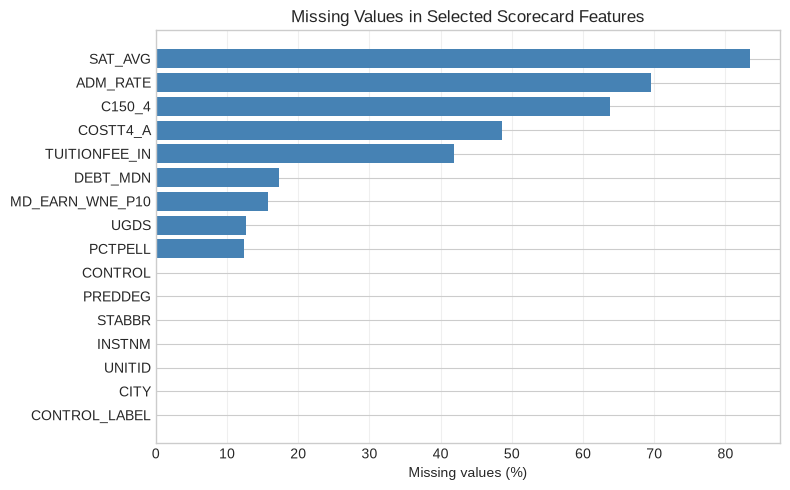

In [ ]:
print(f"Institutions: {scorecard.shape[0]:,}")
print(f"Selected features: {len(selected_columns)}")

# Share of missing values per column, largest first
missing_share = scorecard.isna().mean().sort_values(ascending=False)
print("\nMissing values by feature:")
print((missing_share * 100).round(1))

fig, axis = plt.subplots(figsize=(8, 5))
axis.barh(missing_share.index, missing_share * 100, color="steelblue")
axis.set_xlabel("Missing values (%)")
axis.set_title("Missing Values in Selected Scorecard Features")
axis.invert_yaxis()
axis.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

SAT_AVG is missing for 83.5% of institutions, ADM_RATE is missing for 69.5%, and C150_4 is missing for 63.7%. These would leave much smaller samples for later analyses. DEBT_MDN and MD_EARN_WNE_P10, however, have lower missingness (17.3% and 15.7%), which would support the correlation analysis with a larger sample.

### Hypothesis 1: The median debt is related to the median earnings.
H0: Among bachelor’s-granting institutions (PREDDEG == 3) with both values reported, there is no monotonic association between DEBT_MDN and MD_EARN_WNE_P10 (Spearman ρ = 0).  <br>
HA: There is a monotonic association (ρ != 0).

In [13]:
bachelor = scorecard[scorecard["PREDDEG"] == 3]
complete = bachelor.dropna(subset=["DEBT_MDN", "MD_EARN_WNE_P10"])
print("Complete cases:", len(complete))

rho, p_value = stats.spearmanr(complete["DEBT_MDN"], complete["MD_EARN_WNE_P10"])
print("Overall: rho =", round(rho, 3), " p =", p_value)

Complete cases: 1745
Overall: rho = 0.37  p = 8.648113648537127e-58


The p_value is far below the typical significance level of α = 0.05, thus rejecting the null hypothesis. <br>
The correlation ρ = 0.37 indicates a moderate positive monotonic association between median debt (DEBT_MDN) and median earnings (MD_EARN_WNE_P10).

### Follow Up: Does this relation hold within each institution type?
H0: Within each control type (public, private nonprofit, for-profit), ρ = 0. <br>
HA: Within each control type, ρ != 0.

In [5]:
group_names = ["Public", "Private nonprofit", "Private for-profit"]
number_of_tests = len(group_names)

for group in group_names:
    group_data = complete[complete["CONTROL_LABEL"] == group]
    group_rho, group_p = stats.spearmanr(group_data["DEBT_MDN"], group_data["MD_EARN_WNE_P10"])
    adjusted_p = min(group_p * number_of_tests, 1)
    print(group, ": n =", len(group_data), ", rho =", round(group_rho, 3), ", adjusted p =", adjusted_p)

Public : n = 583 , rho = 0.334 , adjusted p = 3.4893074460463504e-16
Private nonprofit : n = 1034 , rho = 0.383 , adjusted p = 6.392028385933556e-37
Private for-profit : n = 128 , rho = 0.375 , adjusted p = 3.9893432762745547e-05


All three Bonferroni-adjusted p-values are below α, so we reject H0 within each institution type. The correlations are similar in size (ρ = 0.33 to 0.38), and their confidence intervals overlap, so these results do not show that the relationship is stronger in any one type. The main point is that the positive association is not produced by mixing institution types: it appears within each type separately. The correlation is moderate and does not imply that borrowing more causes higher earnings. Both may reflect other factors, such as program mix or cost.

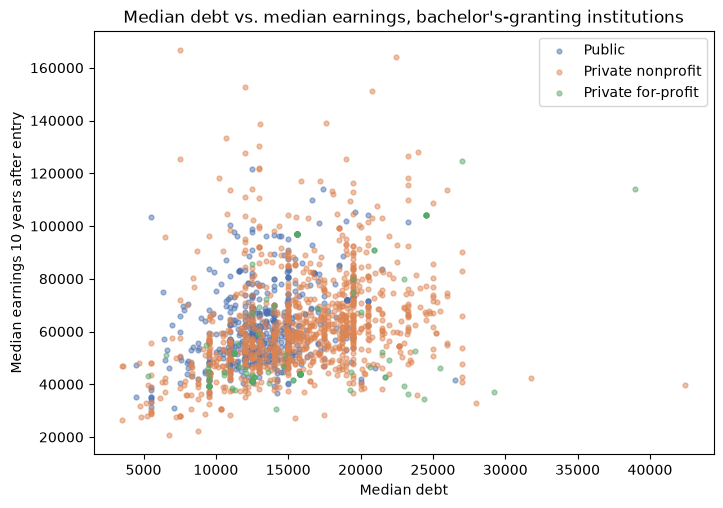

In [6]:
colors = {"Public": "#4C72B0", "Private nonprofit": "#DD8452", "Private for-profit": "#55A868"}
plt.figure(figsize=(8, 5.5))
for group in group_names:
    group_data = complete[complete["CONTROL_LABEL"] == group]
    plt.scatter(group_data["DEBT_MDN"], group_data["MD_EARN_WNE_P10"],
                s=12, alpha=0.5, color=colors[group], label=group)
plt.xlabel("Median debt")
plt.ylabel("Median earnings 10 years after entry")
plt.title("Median debt vs. median earnings, bachelor's-granting institutions")
plt.legend()
plt.show()

### Hypothesis 2: Typical earnings differ by institution type.
H0: Among bachelor's-granting institutions (PREDDEG == 3), median earnings 10 years after entry (MD_EARN_WNE_P10) have the same distribution in public, private nonprofit, and private for-profit institutions. <br>
HA: At least one institution type has a different earnings distribution. <br><br>
We will use the Kruskal–Wallis test instead of one-way ANOVA because earnings are right-skewed within every group and have many high outliers. If H0 is rejected, we use pairwise Mann–Whitney tests with a Bonferroni correction to find which types differ.

In [11]:
group_names = ["Public", "Private nonprofit", "Private for-profit"]

# Collect the earnings of each institution type in a list
earnings_by_group = []
for group in group_names:
    group_earnings = bachelor.loc[bachelor["CONTROL_LABEL"] == group, "MD_EARN_WNE_P10"].dropna()
    earnings_by_group.append(group_earnings)
    print(group, ": n =", len(group_earnings),
          ", median =", group_earnings.median(),
          ", skewness =", round(group_earnings.skew(), 2))

h_stat, p_value = stats.kruskal(earnings_by_group[0], earnings_by_group[1], earnings_by_group[2])
print("Kruskal-Wallis H =", round(h_stat, 1), " p =", p_value)

# Effect size
total_n = len(earnings_by_group[0]) + len(earnings_by_group[1]) + len(earnings_by_group[2])
epsilon_sqr = h_stat / (total_n - 1)
print("ε² =", round(epsilon_sqr, 3))

# Post-hoc: pairwise Mann-Whitney tests with Bonferroni correction
pairs = [(0, 1), (0, 2), (1, 2)]
for first, second in pairs:
    u_stat, pair_p = stats.mannwhitneyu(earnings_by_group[first], earnings_by_group[second])
    adjusted_p = min(pair_p * len(pairs), 1)
    print(group_names[first], "vs", group_names[second], ": adjusted p =", adjusted_p)

Public : n = 587 , median = 59509.0 , skewness = 0.85
Private nonprofit : n = 1089 , median = 59055.0 , skewness = 1.22
Private for-profit : n = 129 , median = 44016.0 , skewness = 1.27
Kruskal-Wallis H = 39.6  p = 2.486220218306518e-09
ε² = 0.022
Public vs Private nonprofit : adjusted p = 1
Public vs Private for-profit : adjusted p = 4.3606374278187864e-11
Private nonprofit vs Private for-profit : adjusted p = 6.576099935752245e-08


The Kruskal–Wallis test rejects H0 (p-value is far below α), so earnings are not distributed identically across institution types. The pairwise comparisons show where the difference lies: private for-profit institutions have lower earnings than both public (adjusted p = 4.36e-11) and private nonprofit institutions (adjusted p = 6.58e-08), whereas public and private nonprofit institutions do not differ (adjusted p = 1.0). <br>

The effect size is small (ε² = 0.02): institution type explains only a small share of the variation in earnings, and the distributions overlap considerably.<br>

These results do not show that attending a private for-profit institution causes lower earnings. The difference may reflect who enrolls or which programs these institutions offer. As in Hypothesis 1, only institutions that report earnings are included, so smaller institutions are under-represented.

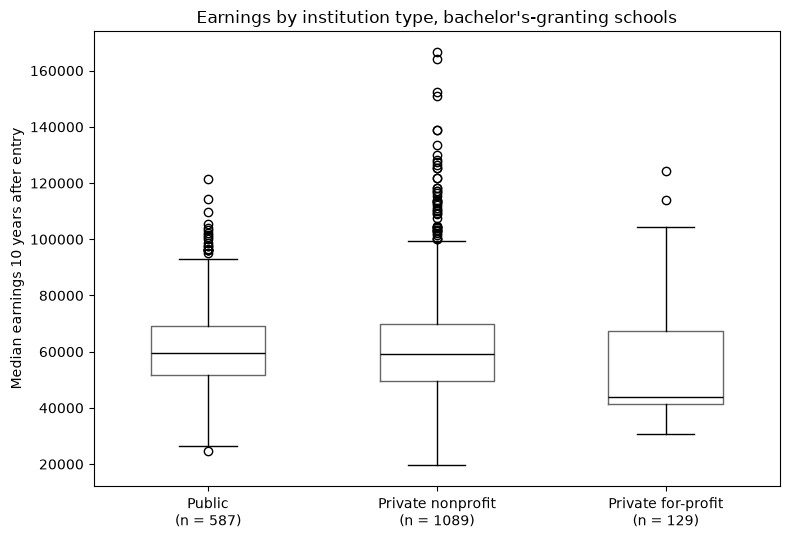

In [18]:
box_labels = []
for i in range(len(group_names)):
    box_labels.append(group_names[i] + "\n(n = " + str(len(earnings_by_group[i])) + ")")

fig, ax = plt.subplots(figsize=(8, 5.5))
boxes = ax.boxplot(earnings_by_group, tick_labels=box_labels, widths=0.5, medianprops={"color": "black"})

for i in range(len(group_names)):
    boxes["boxes"][i].set_alpha(0.6)
    group_median = earnings_by_group[i].median()

ax.set_ylabel("Median earnings 10 years after entry")
ax.set_title("Earnings by institution type, bachelor's-granting schools")
plt.tight_layout()
plt.show()